In [1]:
import pandas as pd
from matplotlib import pyplot as plt
plt.rcParams['font.family'] = 'Times New Roman'

In [2]:
df = pd.read_csv("../data/access/summary.csv", decimal=',', sep=';')

columns_of_interest = [
    "WEIGHTED_ACTIVE_IDX",
    "WEIGHTED_ACTIVE_IDX___EETU",
    "WEIGHTED_ACTIVE_IDX___ECONOMICZONES"
]

scenarios_real = ["real___2013", "real___2022"]
scenarios_solo = [s for s in df["SCENARIO"] if "___solo" in s]

df.head(3)

,ACTIVE_IDX,ACTIVE_IDX___EETU,WEIGHTED_ACTIVE_IDX,WEIGHTED_ACTIVE_IDX___EETU,WEIGHTED_ACTIVE_IDX___ECONOMICZONES,ACTIVE_IDX___ECONOMICZONES,SCENARIO
0,531688.476158,992652.207686,686407.124381,1.066395e+06,873202.215555,847153.915877,real___2013
1,446912.890555,865632.637776,565552.523112,9.284753e+05,734417.620500,713752.045759,real___2022
2,497685.862669,927135.928863,640144.632710,9.948435e+05,808492.279717,786639.317930,jobs___solo


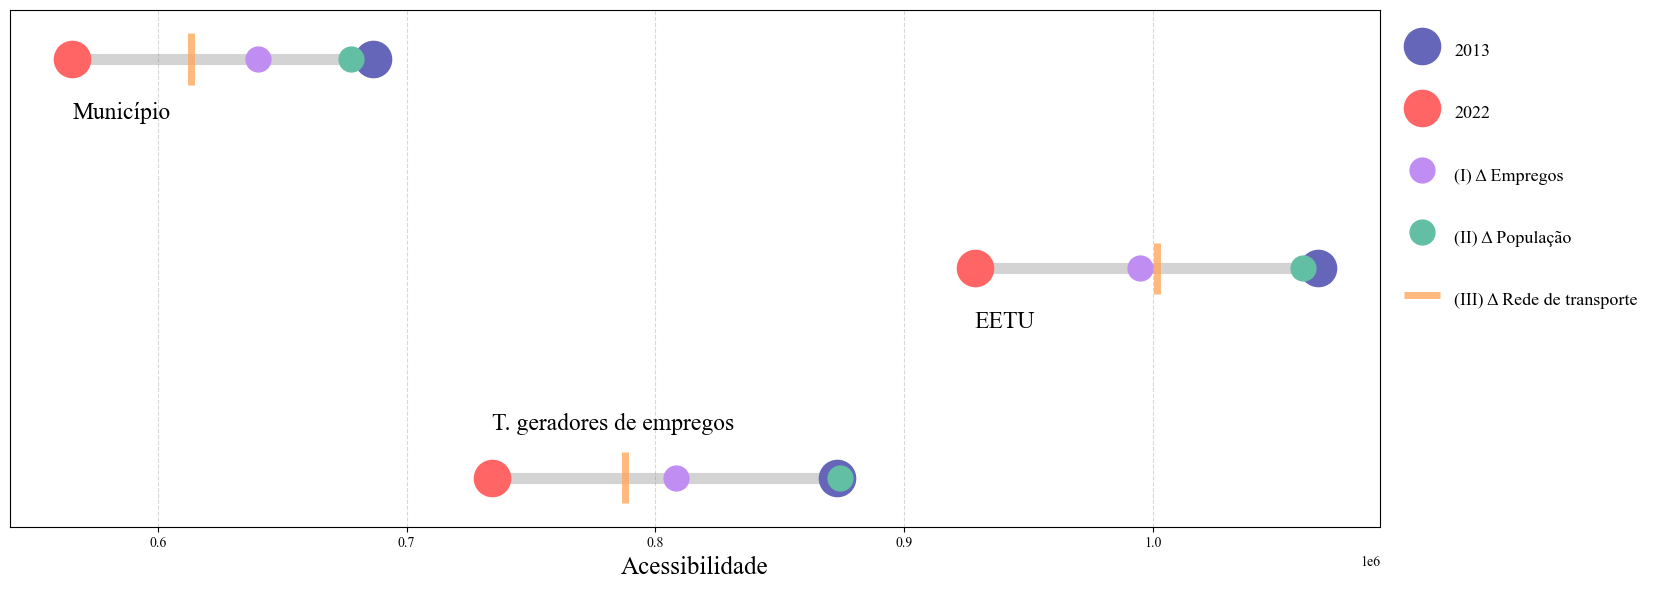

In [3]:
plot_data = []

for col in columns_of_interest:
    # Obter valores dos cenários reais
    base_2013 = df[df["SCENARIO"] == "real___2013"][col].values[0]
    base_2022 = df[df["SCENARIO"] == "real___2022"][col].values[0]
    
    # Obter valores dos cenários "solo"
    values_solo = df[df["SCENARIO"].str.contains("___solo")][["SCENARIO", col]]
    
    plot_data.append({
        "label": col,
        "2013": base_2013,
        "2022": base_2022,
        "scenarios": values_solo
    })

# Plot
fig, ax = plt.subplots(figsize=(14, 6))

for i, data in enumerate(plot_data[::-1]):
    #print("***")
    #print(plot_data[i]["label"])
    col = data["label"]
    y_base = i*0.9 #* 1.1  # Espaçamento vertical entre linhas

    # Range entre 2013 e 2022
    ax.plot([data["2013"], data["2022"]], [y_base, y_base], color="lightgray", linewidth=8, zorder=1)

    # Pontos de 2013 e 2022
    ax.scatter(data["2013"], y_base, color="#6565b9", label="2013" if i == 0 else "", zorder=2, s=680)
    ax.scatter(data["2022"], y_base, color="#ff6565", label="2022" if i == 0 else "", zorder=2, s=680)

    # Pontos dos cenários "solo"
    scenarioTranslation = {
        "jobs___solo": ["(I) Δ Empregos", "#c08ef2"],
        "housing___solo": ["(II) Δ População", "#63bfa3"],
        "network___solo": ["(III) Δ Rede de transporte", "#ffa75d"],
    }
    
    for _, row in data["scenarios"][:-1].iterrows():
     
        if 'network' in row.SCENARIO: continue
        ax.scatter(row[col], y_base, color=scenarioTranslation[row.SCENARIO][1], s=320, zorder=3, label=scenarioTranslation[row.SCENARIO][0])
        """
        ax.vlines(row[col], y_base - 0.11, y_base + 0.11, 
                  color=scenarioTranslation[row.SCENARIO][1], linewidth=5, 
                  alpha=0.8, label=scenarioTranslation[row.SCENARIO][0])
        """
    ax.vlines(row[col], y_base - 0.11, y_base + 0.11, 
                  color=scenarioTranslation["network___solo"][1], linewidth=5, 
                  alpha=0.8, label=scenarioTranslation["network___solo"][0])
        
    
    translation = {
        "WEIGHTED_ACTIVE_IDX___ECONOMICZONES": "T. geradores de empregos",
        "WEIGHTED_ACTIVE_IDX___EETU": "EETU", "WEIGHTED_ACTIVE_IDX": "Município"
    }
    # Label da linha

    realLabel = translation[data["label"]]

    shift = 0.23

    if realLabel=="EETU":
        ax.text(data["2022"], y_base-shift, realLabel, va='center', fontsize=17)
    elif realLabel=="Município":
        ax.text(data["2022"], y_base-shift, realLabel, va='center', fontsize=17)
    else:
        ax.text(data["2022"], y_base+shift, realLabel, va='center', fontsize=17)
    

ax.set_yticks([])
ax.set_xlabel("Acessibilidade", fontsize=18)
#ax.set_title("Intervalos de acessibilidade e cenários contrafactuais", fontsize=14)

#ax.grid(axis='y', linestyle='-.', color='lightgray', visible=True)
plt.grid(axis='x', linestyle='--', color='gray', alpha=0.3)

plt.tight_layout()

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ordered_labels = ["2013", "2022", "(I) Δ Empregos", "(II) Δ População", "(III) Δ Rede de transporte"]
ordered_handles = [by_label[label] for label in ordered_labels]
legend = ax.legend(ordered_handles, ordered_labels, loc='upper right', labelspacing=1.9, bbox_to_anchor=(1.2, 0.98), fontsize=13, handleheight=2)
legend.get_frame().set_edgecolor('none') 

"""
legend = ax.legend(ordered_handles, ordered_labels, loc='upper right', labelspacing=1.9, ncol=2)
plt.tight_layout()
legend.get_frame().set_facecolor('none')   # Remove fundo
legend.get_frame().set_edgecolor('none') 
"""
plt.savefig("./scenarios___range.png", dpi=900)
plt.show()